---
title: "L5-07 · Measurements and instruments"
short_title: "Measurements and instruments"
subtitle: "A measurement has two jobs: a POVM says how likely each record is, and an instrument says what state each record leaves for the next laboratory; equal probabilities never imply equal aftermaths."
description: "Separate the probability of a measurement outcome, fixed by a POVM, from the state that the outcome leaves behind, fixed by a quantum instrument."
tags: [level-5, coursebook]
---

(lesson-l5-07)=

:::{div}
:class: qcai-meta
![Level 5 icon](../../_static/icons/qicon-level-5.svg) **Level 5 · Advanced undergraduate** · about 120 minutes  
**Big idea.** A measurement has two jobs: a POVM says how likely each record is, and an instrument says what state each record leaves for the next laboratory; equal probabilities never imply equal aftermaths.  
**Before this lesson.** [L5-05](#lesson-l5-05), [L5-06](#lesson-l5-06)  
**Lab.** [Qubits and the Bloch sphere](../../labs/05-qubit-bloch.ipynb)
:::

## What you will be able to do

- Compute outcome probabilities $p(a) = \operatorname{Tr}(E_a\rho)$ for projective and non-projective POVMs, and check that a set of operators is a POVM.
- Compute the conditioned state $\rho_a = \mathcal{I}_a(\rho)/p(a)$ for a given instrument, and exhibit two instruments with the same POVM but different conditioned states.
- Prove Naimark's dilation for a finite POVM and the factorization of any instrument as a Lüders step followed by an outcome-dependent channel.
- Quantify the information-disturbance trade-off of a weak Z measurement: outcome bias $\varepsilon$ against coherence factor $\sqrt{1 - \varepsilon^2}$.

## Why this matters

Two laboratories each buy a box labeled 'Z measurement'. Fed the state $|+\rangle$, both boxes print 0 half the time and 1 half the time, run after run, with statistics no test can tell apart. Yet when the output of each box is sent to a third laboratory, one box leaves a state that is perfectly correlated with its printed record and the other leaves a state that has forgotten it. If you model the boxes only by their outcome probabilities, you cannot predict what happens downstream.

This is not an exotic corner case. Photon detectors absorb the photon they count; quantum error correction measures syndromes and must not disturb the encoded data; feedback control acts on the post-measurement state. In causal language, a measurement is an intervention with two outputs: a classical record and a quantum system that flows on. This lesson separates the two cleanly. A **POVM** gives the probabilities; an **instrument** gives the probabilities and the conditioned states. Along the way we prove that every generalized measurement is an ordinary projective one on a bigger system, and we watch a measurement interpolate continuously between doing nothing and full collapse.

:::{dropdown} Key terms

**Projective measurement (PVM)**
: Orthogonal projectors $P_a$ with $\sum_a P_a = I$; outcome $a$ has probability $\operatorname{Tr}(P_a\rho)$.

**POVM**
: Positive operators (effects) $E_a \ge 0$ with $\sum_a E_a = I$. They fix outcome probabilities and nothing else.

**Quantum instrument**
: Completely positive maps $\mathcal{I}_a$, one per outcome, whose sum $\sum_a \mathcal{I}_a$ is a channel (trace preserving).

**Lüders rule**
: The instrument $\rho \mapsto \sqrt{E_a}\,\rho\,\sqrt{E_a}$; for projectors it is projection followed by renormalization.

**Naimark dilation**
: Every POVM is a projective measurement of an ancilla after a unitary interaction with the system.

**Weak (unsharp) measurement**
: A measurement whose effects $\tfrac12(I \pm \varepsilon Z)$ only slightly favor one outcome; small $\varepsilon$ gains little information and disturbs little.

:::


In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))
from qcai.viz import show as _show, show_mpl as _show_mpl
from qcai.lessonfigs import l5_07 as _lessonfigs

## Projective measurement: project, then renormalize

Start with what you know from [L5-01](#lesson-l5-01). Measuring a qubit in the computational basis gives outcome $a \in \{0, 1\}$ with probability $|\langle a|\psi\rangle|^2$. Two facts are hidden in that sentence: the probability is the squared length of a **shadow** (the projection of $|\psi\rangle$ onto the outcome's subspace), and after the outcome the state **is** that shadow, stretched back to unit length.

:::{prf:definition} Projective measurement and the Lüders update
:label: def-l5-07-pvm
A projective measurement on a Hilbert space $\mathcal H$ is a family of orthogonal projectors $\{P_a\}$ with $P_a P_b = \delta_{ab}P_a$ and $\sum_a P_a = I$. On a state $\rho$, outcome $a$ occurs with probability $p(a) = \operatorname{Tr}(P_a\rho)$, and, when $p(a) > 0$, the state after the outcome is $\rho_a = P_a\rho P_a / p(a)$. For a pure state $\rho = |\psi\rangle\langle\psi|$ this is $|\psi_a\rangle = P_a|\psi\rangle / \|P_a|\psi\rangle\|$. This update rule, and its extension $\rho \mapsto \sqrt{E_a}\,\rho\,\sqrt{E_a}$ used below, is named after Lüders [@luders1950].
:::

$$
p(a) = \|P_a|\psi\rangle\|^2 = \langle\psi|P_a|\psi\rangle, \qquad |\psi_a\rangle = \frac{P_a|\psi\rangle}{\sqrt{p(a)}}
$$ (eq-l5-07-luders)

:::{figure} ../../_static/animations/l5_07_project_renormalize.mp4
:alt: The state one half |0> plus root three over two |1> drawn as an arrow at 60 degrees, its shadows on both axes, the blue shadow stretched to |0>, then the same state projected on the |+> direction.
:width: 100%

The Born rule is a squared shadow and the Lüders update is that shadow renormalized. A different basis casts different shadows: $p(+) \approx 0.933$.
:::

:::{dropdown} What the animation shows
The scene draws the real amplitude plane with axes $|0\rangle$ and $|1\rangle$ and the state $|\psi\rangle = \tfrac12|0\rangle + \tfrac{\sqrt{3}}{2}|1\rangle$ as a unit arrow. Dashed lines drop its shadows onto both axes: lengths $1/2$ and $\sqrt3/2$, so $p(0) = 1/4$ and $p(1) = 3/4$. When outcome 0 is recorded, only the blue shadow $\tfrac12|0\rangle$ survives and is divided by $\sqrt{p(0)} = 1/2$, growing into the unit vector $|0\rangle$; measuring Z again now gives 0 with probability 1. The scene then draws the $|+\rangle$ direction at 45 degrees and projects the same state onto it: $\langle +|\psi\rangle = (1 + \sqrt3)/(2\sqrt2)$, so $p(+) = (2 + \sqrt3)/4 \approx 0.933$ and $p(-) = (2 - \sqrt3)/4 \approx 0.067$. The shadow on $|+\rangle$ stretches to the unit vector $|+\rangle$.
:::

Using [](#eq-l5-07-luders) on $|\psi\rangle = \tfrac12|0\rangle + \tfrac{\sqrt3}{2}|1\rangle$: $P_0|\psi\rangle = \tfrac12|0\rangle$, so $p(0) = 1/4$ and $|\psi_0\rangle = |0\rangle$. In the $X$ basis, $\langle +|\psi\rangle = (1 + \sqrt3)/(2\sqrt2)$ and $p(+) = (2 + \sqrt3)/4 \approx 0.933$, while $p(-) = (2 - \sqrt3)/4 \approx 0.067$. The same state, two measurements, two different sets of probabilities and of post-measurement states [@nielsenchuang].

:::{prf:remark} Repeatability is special
Because $P_a^2 = P_a$, a second projective measurement right after the first returns the same outcome with probability $\operatorname{Tr}(P_a\rho_a) = 1$. Most real measurements are not repeatable: a photodetector destroys the photon it counts. The rest of the lesson builds the language for those.
:::

## POVMs: probabilities without the state change

:::{prf:definition} Positive operator-valued measure (POVM)
:label: def-l5-07-povm
A POVM with outcome set $\{1, \dots, m\}$ is a family of operators $E_a$ on $\mathcal H$ with $E_a \ge 0$ (positive semidefinite) and $\sum_a E_a = I$. Each $E_a$ is an **effect**. The outcome probabilities on a state $\rho$ are $p(a) = \operatorname{Tr}(E_a\rho)$.
:::

:::{prf:proposition} The Born rule gives a probability distribution
:label: prop-l5-07-born
For every density operator $\rho$ and POVM $\{E_a\}$, the numbers $p(a) = \operatorname{Tr}(E_a\rho)$ satisfy $p(a) \ge 0$ and $\sum_a p(a) = 1$. Conversely, positivity and completeness are exactly what is needed for this to hold for every $\rho$.
:::

:::{prf:proof}
Write $\rho = \sum_j \lambda_j |j\rangle\langle j|$ with $\lambda_j \ge 0$. Then $\operatorname{Tr}(E_a\rho) = \sum_j \lambda_j \langle j|E_a|j\rangle \ge 0$ because $E_a \ge 0$. Summing, $\sum_a \operatorname{Tr}(E_a\rho) = \operatorname{Tr}(I\rho) = 1$. Conversely, taking $\rho = |v\rangle\langle v|$ for a unit vector $v$ shows $\langle v|E_a|v\rangle \ge 0$ for all $v$, which is $E_a \ge 0$; and $\langle v|\sum_a E_a|v\rangle = 1$ for all unit $v$ forces the Hermitian operator $\sum_a E_a - I$ to vanish.
:::

:::{prf:example} The trine POVM
:label: ex-l5-07-trine
Let $n_0, n_1, n_2$ be unit vectors in the $x$-$z$ plane of the Bloch sphere at $0^\circ$, $120^\circ$ and $240^\circ$ from the $z$ axis, so $n_0 + n_1 + n_2 = 0$. Put $E_k = \tfrac13(I + n_k\cdot\sigma) = \tfrac23|\phi_k\rangle\langle\phi_k|$, where $|\phi_k\rangle$ is the pure state with Bloch vector $n_k$. Then $\sum_k E_k = I + \tfrac13(n_0 + n_1 + n_2)\cdot\sigma = I$. On a state with Bloch vector $r$, using $\operatorname{Tr}(\rho\,\sigma_j) = r_j$, the outcome probabilities are $p(k) = (1 + n_k \cdot r)/3$. A state along $n_0$ gives $(2/3, 1/6, 1/6)$; a state along $-n_0$ gives $(0, 1/2, 1/2)$, so outcome 0 rules that state out with certainty.
:::

:::{figure} ../../_static/animations/l5_07_trine_povm.mp4
:alt: A Bloch sphere with three arrows 120 degrees apart in the x-z plane and a red state arrow sweeping around the great circle, beside three live probability bars.
:width: 100%

Three effects, one qubit. The bars follow $p(k) = (1 + n_k \cdot r)/3$ as the state sweeps the great circle; no bar ever exceeds $2/3$.
:::

:::{dropdown} What the animation shows
A translucent Bloch sphere shows the $x$-$z$ great circle and three arrows $n_0$, $n_1$, $n_2$ that form an equilateral triangle. A side panel writes $E_k = \tfrac23|\phi_k\rangle\langle\phi_k| = \tfrac13(I + n_k\cdot\sigma)$, then $\sum_k E_k = I$ exactly when $n_0 + n_1 + n_2 = 0$, then $p(k) = (1 + n_k \cdot r)/3$. A red state arrow starts along $n_0$; three bars below read $2/3$, $1/6$, $1/6$. As the camera slowly turns, the state sweeps half a turn to $-n_0$, where the bar for outcome 0 drops to zero and the other two read $1/2$: that outcome never occurs for this state. The sweep completes the circle. The closing caption notes that three nonzero outcomes on a two-dimensional space cannot come from orthogonal projectors.
:::


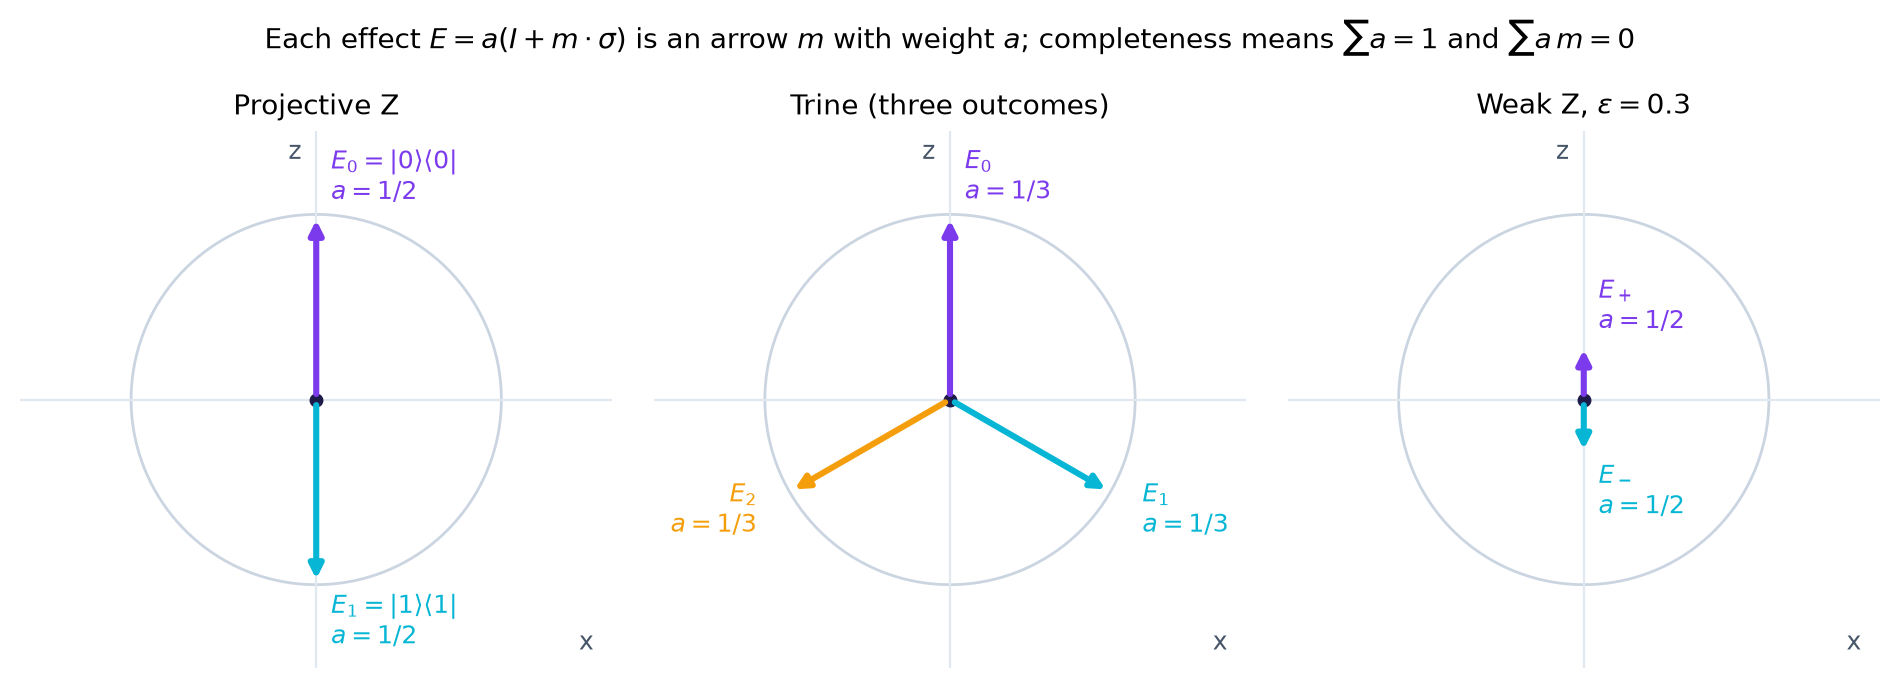

In [2]:
_show_mpl(_lessonfigs.effects_as_arrows())

*Any nonzero qubit effect can be written $E = a(I + m\cdot\sigma)$ with $a > 0$ and $|m| \le 1$; that is exactly what positivity requires. Completeness $\sum E = I$ means the weights add to 1 and the weighted arrows balance at the center. Projective measurements use full-length arrows; the weak measurement of the last section uses short ones.*

:::{prf:theorem} Naimark dilation
:label: thm-l5-07-naimark
Let $\{E_a\}_{a=1}^m$ be a POVM on $\mathcal H$. Define $V : \mathcal H \to \mathcal H \otimes \mathbb C^m$ by $V|\psi\rangle = \sum_a \sqrt{E_a}\,|\psi\rangle \otimes |a\rangle$. Then $V$ is an isometry ($V^\dagger V = I$), and for every state, $\operatorname{Tr}(E_a\rho) = \operatorname{Tr}\big[(I \otimes |a\rangle\langle a|)\,V\rho V^\dagger\big]$. So every POVM is a projective measurement of an ancilla after an isometric (hence, after extension, unitary) interaction.
:::

:::{prf:proof}
$V^\dagger V = \sum_{a,b} \sqrt{E_b}\sqrt{E_a}\,\langle b|a\rangle = \sum_a E_a = I$. For the probabilities, $(I \otimes \langle a|)V|\psi\rangle = \sqrt{E_a}|\psi\rangle$, so $\operatorname{Tr}[(I \otimes |a\rangle\langle a|)V\rho V^\dagger] = \operatorname{Tr}(\sqrt{E_a}\rho\sqrt{E_a}) = \operatorname{Tr}(E_a\rho)$ by cyclicity. Finally, an isometry defined on $\mathcal H \cong \mathcal H \otimes |1\rangle$ maps an orthonormal basis to an orthonormal set, which can be completed to an orthonormal basis of $\mathcal H \otimes \mathbb C^m$; this defines a unitary $U$ with $U(|\psi\rangle \otimes |1\rangle) = V|\psi\rangle$ [@preskill; @watrous].
:::

## Instruments: the outcome and what happens next

A POVM is silent about the state after the measurement. Many physical procedures share the same effects: measure $Z$ and keep the projection; measure $Z$, write the result down and then prepare $|+\rangle$; measure $Z$ and flip the qubit. To describe what flows on, we need one map per outcome.

:::{prf:definition} Quantum instrument
:label: def-l5-07-instrument
An instrument with outcomes $a = 1, \dots, m$ is a family of completely positive maps $\mathcal{I}_a$ from operators on $\mathcal H_{\rm in}$ to operators on $\mathcal H_{\rm out}$ such that $\sum_a \mathcal{I}_a$ is trace preserving (a channel, as in [L5-06](#lesson-l5-06)). Each $\mathcal I_a$ is therefore trace non-increasing. Its effects are defined by $\operatorname{Tr}\mathcal{I}_a(\rho) = \operatorname{Tr}(E_a\rho)$ for all $\rho$; in Kraus form $\mathcal{I}_a(\rho) = \sum_k K_{a,k}\rho K_{a,k}^\dagger$ and $E_a = \sum_k K_{a,k}^\dagger K_{a,k}$.
:::

$$
p(a) = \operatorname{Tr}(E_a\rho) = \operatorname{Tr}\mathcal{I}_a(\rho), \qquad \rho_a = \frac{\mathcal{I}_a(\rho)}{p(a)} \quad (p(a) > 0)
$$ (eq-l5-07-instrument)

:::{warning} Never divide by zero probability
The conditioned state $\rho_a$ in [](#eq-l5-07-instrument) is defined only when $p(a) > 0$. For an outcome that cannot occur on $\rho$ there is no conditioned state, and formulas that seem to give one are artifacts. The unnormalized output $\mathcal I_a(\rho)$ is always defined, and it is often the safer object to carry through a calculation.
:::

:::{figure} ../../_static/animations/l5_07_same_effects.mp4
:alt: Three rows, each an instrument fed |+>: Lüders, record then prepare |+>, record then flip. All three show equal probability bars of one half; the states passed on differ, and later measurements reveal it.
:width: 100%

Identical $p(a) = \operatorname{Tr}(E_a\rho)$, different $\rho_a = \mathcal{I}_a(\rho)/p(a)$. Only a later laboratory can tell the three boxes apart.
:::

:::{dropdown} What the animation shows
Each of three rows feeds $|+\rangle$ into a different box. Row one keeps the projection (Lüders) and passes on $|0\rangle$ or $|1\rangle$; row two records the outcome then prepares $|+\rangle$; row three records the outcome then flips the qubit, passing on $|1\rangle$ or $|0\rangle$. All three show the same outcome bars, one half and one half, and a red box marks them as identical, with the formula $p(a) = \operatorname{Tr}(E_a\rho)$. Two new columns describe a later laboratory. A later X measurement gives $+$ with probability 1/2, 1 and 1/2 for the three rows. A later Z measurement matches the recorded outcome always, half the time, and never. The formula $\rho_a = \mathcal{I}_a(\rho)/p(a)$ is highlighted: the conditioned states differ.
:::

:::{prf:proposition} Every instrument is a Lüders step followed by a channel
:label: prop-l5-07-factor
Let $\{\mathcal I_a\}$ be an instrument on a finite-dimensional space with effects $\{E_a\}$. Then there are channels $\Lambda_a$ such that $\mathcal{I}_a(\rho) = \Lambda_a\big(\sqrt{E_a}\,\rho\,\sqrt{E_a}\big)$ for every $\rho$ and every $a$. In particular, two instruments with the same POVM differ only by what they do after the Lüders step, and that may depend on the outcome.
:::

:::{prf:proof}
Fix $a$ and a Kraus form $\mathcal I_a(\rho) = \sum_k K_{a,k}\rho K_{a,k}^\dagger$ with $\sum_k K_{a,k}^\dagger K_{a,k} = E_a$. Let $\Pi_a$ be the projector onto the support (range) of $E_a$ and $E_a^{-1/2}$ the inverse of $\sqrt{E_a}$ on that support, extended by $0$ on the kernel. If $E_a v = 0$, then $\sum_k \|K_{a,k}v\|^2 = \langle v|E_a|v\rangle = 0$, so $K_{a,k}v = 0$; hence $K_{a,k} = K_{a,k}\Pi_a = L_{a,k}\sqrt{E_a}$ with $L_{a,k} = K_{a,k}E_a^{-1/2}$. These satisfy $\sum_k L_{a,k}^\dagger L_{a,k} = E_a^{-1/2}E_aE_a^{-1/2} = \Pi_a$. Complete this to a channel by adding a term that acts only on the kernel: $\Lambda_a(X) = \sum_k L_{a,k}XL_{a,k}^\dagger + \operatorname{Tr}[(I - \Pi_a)X]\,\sigma$ for any fixed state $\sigma$ on $\mathcal H_{\rm out}$. It is completely positive, and trace preserving because $\operatorname{Tr}\sum_k L_{a,k}XL_{a,k}^\dagger = \operatorname{Tr}(\Pi_a X)$. The extra term vanishes on $\sqrt{E_a}\rho\sqrt{E_a}$, whose support lies in $\Pi_a$, so $\Lambda_a(\sqrt{E_a}\rho\sqrt{E_a}) = \sum_k L_{a,k}\sqrt{E_a}\rho\sqrt{E_a}L_{a,k}^\dagger = \mathcal I_a(\rho)$.
:::

```{mermaid}
graph LR
  R["state ρ"] --> I["instrument: maps I_a"]
  I -->|"record a"| C["classical log"]
  I -->|"system in state ρ_a"| N["next laboratory"]
  C -.->|"may steer"| N
```

*An instrument has two outputs: a classical record and a quantum system. A POVM describes only the first arrow. In a causal model both arrows are edges, and the record may also control what the next laboratory does [@costa].*

For the three boxes of the animation (input $|+\rangle$, effects $|0\rangle\langle 0|$ and $|1\rangle\langle 1|$), the channels $\Lambda_a$ of [](#prop-l5-07-factor) are: the identity for the Lüders box; 'discard and prepare $|+\rangle$' for the second box; and $\rho \mapsto X\rho X$ for the third. The second box breaks the correlation between record and system, the third reverses it. This is why a causal model of a quantum experiment must specify the instrument, not just the POVM, at every node where a system is measured and then passed on [@costa].

## Weak measurement: trading information for disturbance

Between doing nothing and a full projective measurement lies a continuous family. Fix a strength $\varepsilon \in [0, 1]$ and take the effects $E_\pm = \tfrac12(I \pm \varepsilon Z)$ with the Lüders instrument $M_\pm = \sqrt{E_\pm}$, that is $M_+ = \operatorname{diag}\big(\sqrt{(1+\varepsilon)/2}, \sqrt{(1-\varepsilon)/2}\big)$ and $M_-$ with the entries swapped. At $\varepsilon = 0$ both outcomes are coin flips and nothing happens to the state; at $\varepsilon = 1$ this is the projective $Z$ measurement. (Here 'weak' means unsharp; it is unrelated to the 'weak values' of postselected experiments.)

Write the state as $\rho = \tfrac12(I + xX + yY + zZ)$. Multiplying out $M_\pm\rho M_\pm$ gives the outcome probabilities $p(\pm) = (1 \pm \varepsilon z)/2$, and the conditioned Bloch vectors

$$
z' = \frac{z \pm \varepsilon}{1 \pm \varepsilon z}, \qquad x' = \frac{\sqrt{1 - \varepsilon^2}\,x}{1 \pm \varepsilon z}, \qquad y' = \frac{\sqrt{1 - \varepsilon^2}\,y}{1 \pm \varepsilon z}
$$ (eq-l5-07-weak)

Averaging over the outcome (no record kept) gives $\sum_\pm M_\pm\rho M_\pm$, whose Bloch vector is $(\sqrt{1 - \varepsilon^2}\,x, \sqrt{1 - \varepsilon^2}\,y, z)$: a dephasing channel. The information gained is measured by the outcome bias $p(+|\,|0\rangle) - p(+|\,|1\rangle) = \varepsilon$; the coherence that survives is $\sqrt{1 - \varepsilon^2}$. Their squares add to one, so each unit of information is paid for in coherence.

:::{figure} ../../_static/animations/l5_07_weak_to_strong.mp4
:alt: A Bloch disk with the state |+>. As the strength grows, two conditioned states slide along the circle toward |0> and |1> while their average moves toward the center; then sixteen seeded trajectories of z under repeated weak measurements run to plus or minus one.
:width: 100%

Left: conditioned states stay pure, on the circle at $(\sqrt{1 - \varepsilon^2}, \pm\varepsilon)$, while their average loses coherence. Right: repeated weak measurements, each updating $z' = \frac{z \pm \varepsilon}{1 \pm \varepsilon z}$, collapse the state gradually.
:::

:::{dropdown} What the animation shows
The scene shows the $x$-$z$ Bloch disk and the state $|+\rangle$ at $(1, 0)$, with the effects $E_\pm = \tfrac12(I \pm \varepsilon Z)$ and $M_\pm = \sqrt{E_\pm}$. As $\varepsilon$ grows from 0 to 1, a blue dot (after outcome $+$) and an orange dot (after outcome $-$) slide along the circle to $(\sqrt{1 - \varepsilon^2}, \pm\varepsilon)$, staying pure, while a red dot for their average sits on the chord at $(\sqrt{1 - \varepsilon^2}, 0)$. Two bars show information $\varepsilon$ rising and coherence $\sqrt{1 - \varepsilon^2}$ falling; at $\varepsilon = 1$ the measurement is projective and all coherence is gone. The update rule $z' = \frac{z \pm \varepsilon}{1 \pm \varepsilon z}$ is written. In the second part, sixteen seeded simulated runs of 60 repeated measurements with $\varepsilon = 0.3$, all starting at $z = 0$, are plotted as $z_n$ against $n$. Each run drifts and then locks onto $+1$ or $-1$. In this seeded run 8 of 16 end near $|0\rangle$ and 8 near $|1\rangle$, matching the Born rule prediction of one half each, and the panel states the martingale property $\mathbb{E}[z'] = z$.
:::


In [3]:
_show(_lessonfigs.weak_measurement())

**Explore.** Pick a starting state from the menu and drag the strength $\varepsilon$. Watch the two conditioned states stay on the circle while the average falls inside it.

:::{dropdown} What the figure shows
The first panel is the Bloch disk with axes $x$ and $z$. It shows the chosen starting state (a diamond), the states after outcome $+$ and after outcome $-$ given by [](#eq-l5-07-weak), the dotted chord joining them, and the outcome-averaged state $(\sqrt{1 - \varepsilon^2}\,x, z)$. The second panel shows bars for $p(+) = (1 + \varepsilon z)/2$, $p(-) = (1 - \varepsilon z)/2$ and the coherence factor $\sqrt{1 - \varepsilon^2}$. The menu offers $|+\rangle$, a state tilted up to Bloch angle $45^\circ$, and one tilted down to $120^\circ$; the slider runs $\varepsilon$ from 0 to 1 in steps of 0.1.
:::

:::{prf:proposition} Gradual collapse obeys the Born rule
:label: prop-l5-07-martingale
Under repeated weak $Z$ measurements, $z_n$ is a martingale: $\mathbb E[z_{n+1} \mid z_n] = z_n$. Moreover $\operatorname{artanh} z_{n+1} = \operatorname{artanh} z_n \pm \operatorname{artanh}\varepsilon$, so each outcome is a fixed step in this variable, and with $0 < \varepsilon < 1$ the state approaches $|0\rangle$ or $|1\rangle$ with probabilities $(1 + z_0)/2$ and $(1 - z_0)/2$.
:::

:::{prf:proof}
From $p(\pm) = (1 \pm \varepsilon z)/2$ and [](#eq-l5-07-weak), $\mathbb E[z'] = \frac{1 + \varepsilon z}{2}\cdot\frac{z + \varepsilon}{1 + \varepsilon z} + \frac{1 - \varepsilon z}{2}\cdot\frac{z - \varepsilon}{1 - \varepsilon z} = \frac{(z + \varepsilon) + (z - \varepsilon)}{2} = z$. The step rule is the addition formula $\tanh(u \pm v) = (\tanh u \pm \tanh v)/(1 \pm \tanh u\tanh v)$ with $z = \tanh u$, $\varepsilon = \tanh v$. A bounded martingale converges almost surely. Each step changes $z$ by $\varepsilon(1 - z^2)/(1 \pm \varepsilon z)$ in absolute value, which stays bounded away from zero unless $|z| \to 1$, so the limit must be $\pm 1$. Its mean equals $z_0$, so $P(z_\infty = 1)\cdot 1 + P(z_\infty = -1)\cdot(-1) = z_0$, giving $P(z_\infty = 1) = (1 + z_0)/2$, the Born probability of outcome 0.
:::

## Compute it

Build the trine POVM, check positivity and completeness, compute its probabilities, and verify Naimark's isometry numerically (`psd_sqrt` computes $\sqrt{E_k}$ from an eigendecomposition).


In [4]:
import numpy as np
from qcai import science as qs

I2 = np.eye(2)

def psd_sqrt(A):
    w, U = np.linalg.eigh(A)
    return U @ np.diag(np.sqrt(np.clip(w, 0, None))) @ U.conj().T

X = np.array([[0, 1], [1, 0]], dtype=complex)
Z = np.diag([1.0, -1.0]).astype(complex)

# Trine POVM: E_k = (1/3)(I + n_k . sigma), with n_k in the x-z plane at 0, 120 and 240 degrees
ns = [(np.sin(2 * np.pi * k / 3), np.cos(2 * np.pi * k / 3)) for k in range(3)]      # (x, z)
E = [(I2 + nx * X + nz * Z) / 3 for nx, nz in ns]
print('effects sum to I:', np.allclose(sum(E), I2))
print('eigenvalues of each effect:', [(np.round(np.linalg.eigvalsh(e), 4) + 0.0).tolist() for e in E])

for name, theta in [('|0>', 0.0), ('|1>', np.pi), ('|+>', np.pi / 2)]:
    rho = qs.dm(qs.ket(theta))
    p = [float(np.trace(e @ rho).real) for e in E]
    print(f'trine probabilities for {name}:', np.round(p, 4), ' sum =', round(sum(p), 12))

# Naimark dilation: V|psi> = sum_k sqrt(E_k)|psi> (x) |k>, an isometry from C^2 into C^2 (x) C^3
V = sum(np.kron(psd_sqrt(e), np.eye(3)[:, [k]]) for k, e in enumerate(E))
print('V^dagger V = I (isometry):', np.allclose(V.conj().T @ V, I2))
big = (V @ qs.ket(np.pi / 2)).reshape(2, 3)          # system index, ancilla index
print('ancilla projective measurement on |+>:', np.round([np.linalg.norm(big[:, k]) ** 2 for k in range(3)], 4))

effects sum to I: True
eigenvalues of each effect: [[0.0, 0.6667], [0.0, 0.6667], [0.0, 0.6667]]
trine probabilities for |0>: [0.6667 0.1667 0.1667]  sum = 1.0
trine probabilities for |1>: [0.  0.5 0.5]  sum = 1.0
trine probabilities for |+>: [0.3333 0.622  0.0447]  sum = 1.0
V^dagger V = I (isometry): True
ancilla projective measurement on |+>: [0.3333 0.622  0.0447]


Three instruments with the same effects on $|+\rangle$, and the weak $Z$ measurement with $\varepsilon = 0.6$ (the worked example).


In [5]:
# Three instruments with the same effects {|0><0|, |1><1|}, applied to |+>
P = [np.diag([1.0, 0.0]).astype(complex), np.diag([0.0, 1.0]).astype(complex)]
plus = qs.dm(qs.ket(np.pi / 2))
instruments = {
    'Lueders':     lambda a, r: P[a] @ r @ P[a],
    'prepare |+>': lambda a, r: np.trace(P[a] @ r) * plus,
    'flip':        lambda a, r: X @ P[a] @ r @ P[a] @ X,
}
for name, inst in instruments.items():
    p = [float(np.trace(inst(a, plus)).real) for a in (0, 1)]
    post = [inst(a, plus) / p[a] for a in (0, 1)]
    later_plus = [float(np.trace(post[a] @ (I2 + X) / 2).real) for a in (0, 1)]
    agree = sum(p[a] * float(np.trace(post[a] @ P[a]).real) for a in (0, 1))
    print(f'{name:12s} p(a) = {np.round(p, 3).tolist()}  later p(+) = {np.round(later_plus, 3).tolist()}  later Z agrees: {agree:.2f}')

# Weak (unsharp) Z measurement, strength eps: Lueders instrument of E_pm = (I pm eps Z)/2
eps = 0.6
c, s = np.sqrt((1 + eps) / 2), np.sqrt((1 - eps) / 2)
M = {'+': np.diag([c, s]).astype(complex), '-': np.diag([s, c]).astype(complex)}
print('Kraus completeness:', np.allclose(sum(m.conj().T @ m for m in M.values()), I2))
for k, m in M.items():
    out = m @ plus @ m.conj().T
    pk = float(np.trace(out).real)
    print(f'outcome {k}: p = {pk:.3f}, Bloch vector after = {np.round(qs.bloch(out / pk), 3).tolist()}')
avg = sum(m @ plus @ m.conj().T for m in M.values())
print('average Bloch vector:', np.round(qs.bloch(avg), 3).tolist(), ' sqrt(1 - eps^2) =', round(np.sqrt(1 - eps ** 2), 3))

Lueders      p(a) = [0.5, 0.5]  later p(+) = [0.5, 0.5]  later Z agrees: 1.00
prepare |+>  p(a) = [0.5, 0.5]  later p(+) = [1.0, 1.0]  later Z agrees: 0.50
flip         p(a) = [0.5, 0.5]  later p(+) = [0.5, 0.5]  later Z agrees: 0.00
Kraus completeness: True
outcome +: p = 0.500, Bloch vector after = [0.8, 0.0, 0.6]
outcome -: p = 0.500, Bloch vector after = [0.8, 0.0, -0.6]
average Bloch vector: [0.8, 0.0, 0.0]  sqrt(1 - eps^2) = 0.8


A seeded simulation of 2000 runs of 150 repeated weak measurements from $z_0 = 0.5$. The fraction of runs that end near $|0\rangle$ should be close to the Born probability $0.75$; this is a check of [](#prop-l5-07-martingale), not an experiment.


In [6]:
# Repeated weak measurements (a seeded simulation, not an experiment)
rng = np.random.default_rng(5)

def run(eps=0.3, z=0.5, n=150):
    for _ in range(n):
        sgn = 1 if rng.random() < (1 + eps * z) / 2 else -1
        z = (z + sgn * eps) / (1 + sgn * eps * z)
    return z

ends = np.array([run() for _ in range(2000)])
print('start z = 0.5, so the Born rule gives p(0) = (1 + z)/2 = 0.75')
print('fraction of runs ending with z > 0.99:', (ends > 0.99).mean())
print('fraction ending with z < -0.99:     ', (ends < -0.99).mean())
print('runs still undecided after 150 steps: ', ((ends > -0.99) & (ends < 0.99)).mean())
print('mean final z (martingale: stays 0.5 on average):', round(ends.mean(), 3))

start z = 0.5, so the Born rule gives p(0) = (1 + z)/2 = 0.75
fraction of runs ending with z > 0.99: 0.7585
fraction ending with z < -0.99:      0.241
runs still undecided after 150 steps:  0.0005
mean final z (martingale: stays 0.5 on average): 0.517


:::{prf:remark} What the numbers show
The trine effects have eigenvalues $2/3$ and $0$: positive, rank one, but not projectors. For $|+\rangle$ the trine gives $p(0) = 1/3$, $p(1) = (1 + \sqrt3/2)/3 \approx 0.622$ and $p(2) = (1 - \sqrt3/2)/3 \approx 0.045$. The three $Z$ instruments print identical $p(a)$ but different later statistics, and the weak measurement leaves pure conditioned states $(0.8, 0, \pm 0.6)$ with an average $(0.8, 0, 0)$.
:::

## Worked example

:::{admonition} A weak measurement of |+> with strength 0.6
:class: tip

Apply the Lüders instrument of $E_\pm = \tfrac12(I \pm 0.6\,Z)$ to $|+\rangle$. Find $p(\pm)$, the conditioned states, the outcome-averaged state, and the probability that a later $X$ measurement gives $+$ when the record is discarded.

1. The Bloch vector of $|+\rangle$ is $(x, y, z) = (1, 0, 0)$, so $p(\pm) = (1 \pm 0.6\cdot 0)/2 = 1/2$.
2. By [](#eq-l5-07-weak), $z' = \pm 0.6$ and $x' = \sqrt{1 - 0.36} = 0.8$. The conditioned states have Bloch vectors $(0.8, 0, \pm 0.6)$, of length 1: they are pure. Explicitly $M_+|+\rangle = (\sqrt{0.8}|0\rangle + \sqrt{0.2}|1\rangle)/\sqrt2$, which normalizes to $\sqrt{0.8}|0\rangle + \sqrt{0.2}|1\rangle$, with $z = 0.8 - 0.2 = 0.6$ and $x = 2\sqrt{0.16} = 0.8$.
3. Averaging with weights $1/2$ gives $(0.8, 0, 0)$: the coherence factor is $\sqrt{1 - \varepsilon^2} = 0.8$ and the state is mixed, with purity $\tfrac12(1 + 0.64) = 0.82$.
4. A later $X$ measurement gives $+$ with probability $(1 + x)/2 = (1 + 0.8)/2 = 0.9$, down from 1 before the weak measurement.

**Result.** Each outcome has probability $1/2$ and leaves a pure state $(0.8, 0, \pm 0.6)$; forgetting the record leaves $(0.8, 0, 0)$, and the chance of $+$ in a later $X$ test falls from 1 to $0.9$.
:::

## Exercises

**1. (Core)** Compute the trine probabilities $p(0), p(1), p(2)$ for the state $|+\rangle$ and check that they add to 1.

:::{dropdown} Solution
$r = (1, 0, 0)$, $n_0 = (0, 0, 1)$, $n_1 = (\sqrt3/2, 0, -1/2)$, $n_2 = (-\sqrt3/2, 0, -1/2)$. So $p(0) = 1/3$, $p(1) = (1 + \sqrt3/2)/3 \approx 0.622$, $p(2) = (1 - \sqrt3/2)/3 \approx 0.045$. The sum is $(3 + 0)/3 = 1$.
:::

**2. (Core)** A device measures $Z$, records the outcome, then always prepares $|+\rangle$. Write its instrument $\mathcal I_a$, its effects, and the probability of outcome 1 in a later $Z$ measurement.

:::{dropdown} Solution
$\mathcal I_a(\rho) = \operatorname{Tr}(|a\rangle\langle a|\rho)\,|+\rangle\langle +|$ for $a = 0, 1$. Its effects are $E_a = |a\rangle\langle a|$, since $\operatorname{Tr}\mathcal I_a(\rho) = \langle a|\rho|a\rangle$. Whatever the outcome, the system leaves in $|+\rangle$, so a later $Z$ measurement gives 1 with probability $1/2$. The effects alone would not have told you this.
:::

**3. (Stretch)** Show that no projective measurement on a qubit has three outcomes with nonzero projectors, and conclude that the trine POVM is not projective. Then show that each trine effect has eigenvalues $2/3$ and $0$.

:::{dropdown} Solution
Mutually orthogonal nonzero projectors have ranks at least 1 that add to at most $\dim\mathcal H = 2$ (since $\sum_a P_a = I$ has trace 2), so at most two can be nonzero. The trine has three nonzero effects, hence is not projective. $E_k = \tfrac13(I + n_k\cdot\sigma)$, and $n_k\cdot\sigma$ has eigenvalues $\pm 1$ because $|n_k| = 1$, so $E_k$ has eigenvalues $\tfrac13(1 \pm 1) = 2/3, 0$; then $E_k^2 = \tfrac23 E_k \ne E_k$.
:::

**4. (Stretch)** Derive $p(\pm) = (1 \pm \varepsilon z)/2$ and the update [](#eq-l5-07-weak) for $z'$ from $M_\pm = \sqrt{E_\pm}$, $E_\pm = \tfrac12(I \pm \varepsilon Z)$.

:::{dropdown} Solution
$M_+ = \operatorname{diag}(\alpha, \beta)$ with $\alpha^2 = (1+\varepsilon)/2$, $\beta^2 = (1-\varepsilon)/2$. The diagonal of $\rho$ is $((1+z)/2, (1-z)/2)$, so $M_+\rho M_+$ has diagonal $(\alpha^2(1+z)/2, \beta^2(1-z)/2)$. Its trace is $[(1+\varepsilon)(1+z) + (1-\varepsilon)(1-z)]/4 = (1 + \varepsilon z)/2 = p(+)$. Its $z$ component is the difference of the diagonal entries, $[(1+\varepsilon)(1+z) - (1-\varepsilon)(1-z)]/4 = (z + \varepsilon)/2$; dividing by $p(+)$ gives $z' = (z + \varepsilon)/(1 + \varepsilon z)$. The off-diagonal entry is multiplied by $\alpha\beta = \sqrt{1 - \varepsilon^2}/2$, which gives $x' = \sqrt{1-\varepsilon^2}\,x/(1 + \varepsilon z)$ after dividing by $p(+)$ (and the same for $y$). The $-$ outcome follows by $\varepsilon \to -\varepsilon$.
:::

**5. (Challenge)** Construct a unitary dilation for the weak measurement: find a unitary $U$ on system plus ancilla qubit and an ancilla start state such that a $Z$ measurement of the ancilla realizes the instrument $M_\pm$. Hint: a controlled rotation.

:::{dropdown} Solution
Write $\sqrt{(1+\varepsilon)/2} = \cos\chi$ and $\sqrt{(1-\varepsilon)/2} = \sin\chi$ with $\chi \in [0, \pi/4]$. Start the ancilla in $|0\rangle$ and apply $U = |0\rangle\langle 0| \otimes R_y(2\chi) + |1\rangle\langle 1| \otimes R_y(\pi - 2\chi)$ (system first), where $R_y(t)|0\rangle = \cos(t/2)|0\rangle + \sin(t/2)|1\rangle$. For system $|0\rangle$ the ancilla becomes $\cos\chi|0\rangle + \sin\chi|1\rangle$; for system $|1\rangle$ it becomes $\sin\chi|0\rangle + \cos\chi|1\rangle$. Projecting the ancilla on $|0\rangle$ applies $\operatorname{diag}(\cos\chi, \sin\chi) = M_+$ to the system, and on $|1\rangle$ applies $\operatorname{diag}(\sin\chi, \cos\chi) = M_-$. $U$ is unitary because it is block diagonal with unitary blocks.
:::

**6. (Challenge)** Two instruments have the same POVM $\{E_a\}$. Show that if they differ, some experiment that keeps both the record and the output system can tell them apart with nonzero bias, even though the records alone cannot.

:::{dropdown} Solution
If $\mathcal I_a \ne \mathcal I'_a$ for some $a$, there is a state $\rho$ and an operator $0 \le F \le I$ with $\operatorname{Tr}[F\mathcal I_a(\rho)] \ne \operatorname{Tr}[F\mathcal I'_a(\rho)]$ (two different linear maps differ on some density operator, because density operators span all operators; and two different operators $\mathcal I_a(\rho) \ne \mathcal I'_a(\rho)$ are separated by some effect $F$, for example a spectral projector of their Hermitian difference). Prepare $\rho$, apply the instrument, and when the record is $a$ measure $\{F, I - F\}$. The joint probability $p(a, F)$ equals $\operatorname{Tr}[F\mathcal I_a(\rho)]$, which differs between the two instruments, while $p(a) = \operatorname{Tr}(E_a\rho)$ is the same for both.
:::

## Check your understanding

**1. What does an instrument specify that a POVM does not?**

- **A.** The number of outcomes
- **B.** A different rule for outcome probabilities
- **C.** The state left behind for each recorded outcome
- **D.** A hidden variable that fixes each outcome

:::{dropdown} Show the answer
**C. The state left behind for each recorded outcome**

A POVM fixes $p(a) = \operatorname{Tr}(E_a\rho)$. An instrument also fixes the maps $\mathcal I_a$, hence the conditioned states $\rho_a = \mathcal I_a(\rho)/p(a)$; its probabilities follow the same Born rule.
:::

**2. For the trine POVM, a qubit has Bloch vector $-n_0$. What is the probability of outcome 0?**

- **A.** 1/6
- **B.** 2/3
- **C.** 1/3
- **D.** 0

:::{dropdown} Show the answer
**D. 0**

$p(0) = (1 + n_0\cdot(-n_0))/3 = (1 - 1)/3 = 0$. Seeing outcome 0 therefore rules this state out.
:::

**3. After a weak $Z$ measurement of strength $\varepsilon$ with the record discarded, the $x$ component of the Bloch vector is multiplied by**

- **A.** $1 - \varepsilon$
- **B.** $\sqrt{1 - \varepsilon^2}$
- **C.** 1
- **D.** $\varepsilon$

:::{dropdown} Show the answer
**B. $\sqrt{1 - \varepsilon^2}$**

The average of $M_\pm\rho M_\pm$ multiplies each off-diagonal entry by $2\sqrt{(1+\varepsilon)/2}\sqrt{(1-\varepsilon)/2} = \sqrt{1 - \varepsilon^2}$, and $z$ is unchanged.
:::

**4. Kraus operators $\{K_j\}$ define a trace-preserving channel exactly when** *(Review of [L5-06](#lesson-l5-06))*

- **A.** $\sum_j K_j K_j^\dagger = I$
- **B.** each $K_j$ is unitary
- **C.** $\sum_j K_j^\dagger K_j = I$
- **D.** $\sum_j K_j = I$

:::{dropdown} Show the answer
**C. $\sum_j K_j^\dagger K_j = I$**

$\operatorname{Tr}\sum_j K_j\rho K_j^\dagger = \operatorname{Tr}(\sum_j K_j^\dagger K_j\,\rho)$ equals $\operatorname{Tr}\rho$ for all $\rho$ exactly when $\sum_j K_j^\dagger K_j = I$. The other sum equal to $I$ is the condition for a unital channel.
:::

## Common misconceptions

- **"After a measurement the system is always in an eigenstate of the measured observable."** That is the Lüders (projective) instrument only. Other instruments with the same effects may prepare any state, destroy the system (a photodetector), or leave it nearly undisturbed (a weak measurement). The outcome statistics do not decide which.
- **"A POVM is just a noisy projective measurement."** Some POVMs are coarse-grained or noisy versions of projective ones, but others, like the trine, are extremal and do things no qubit projective measurement can, such as excluding one of three states with certainty. By Naimark's theorem every POVM is a projective measurement on a larger system.
- **"Collapse is always sudden and complete."** For an unsharp measurement the conditioned state moves only part of the way, $z' = \frac{z \pm \varepsilon}{1 \pm \varepsilon z}$. Repeating such measurements produces gradual collapse that still reproduces the Born probabilities.

:::{caution} Scope and limits
Everything here is finite-dimensional with finitely many outcomes; continuous outcomes need measure theory. Conditioned states are defined only for outcomes with $p(a) > 0$. The weak measurement is the unsharp Lüders instrument, not a weak-value experiment, and the random-walk results are seeded simulations of the model, not data. Naimark's dilation is a mathematical representation: it says a POVM can be implemented with an ancilla, not that every apparatus contains one.
:::

:::{seealso} Where this leads
Instruments are the building blocks of the next lessons. In [L5-08](#lesson-l5-08) two separated parties each apply a measurement to half of an entangled state, and only the outcome probabilities matter. In [L5-09](#lesson-l5-09) repeated measurements reconstruct a state, and in [L5-10](#lesson-l5-10) syndrome measurements must be instruments that reveal the error without revealing the data. In Level 6 the Choi representation of each $\mathcal I_a$ becomes a node of a quantum causal model.
:::

:::{dropdown} For instructors

**Why this lesson.** Students often leave a first course believing that measurement means 'project onto an eigenstate'. Quantum information, error correction and quantum causal modeling all need the finer split between what is recorded and what flows on. The instrument formalism makes that split explicit, and the factorization proposition shows exactly how much freedom it adds [@nielsenchuang; @watrous; @costa].

**Teaching notes.**

- Open with the two 'Z measurement' boxes. Ask students to design a test that tells them apart before showing the animation; most first propose comparing outcome statistics, which fails.
- Have students draw the trine effects as arrows (the figure) and verify completeness geometrically before computing; then check $p(k)$ for $\pm n_0$.
- Use the interactive to show that conditioned states stay pure for a pure input, while the average is mixed: information is not lost by the instrument, only by forgetting the record.
- Preskill's notes treat POVMs and Naimark's theorem in chapter 3; Watrous treats instruments in the chapter on measurements [@preskill; @watrous].

**Assessment.** The second core exercise and the instrument check question test the central distinction. The stretch derivation of the weak-measurement update and the first challenge (a unitary dilation) test whether students can move between Kraus operators, effects and circuits.

**Going further.** Show that the weak measurement with $\varepsilon = \tanh v$ composes like rapidities: two measurements of strengths $\varepsilon_1, \varepsilon_2$ with equal outcomes act like one of strength $(\varepsilon_1 + \varepsilon_2)/(1 + \varepsilon_1\varepsilon_2)$ on $z$ (check whether the $x$ coherence factors also compose). Then read the section on instruments and process-based causal models in Costa and Shrapnel [@costa].

:::

## References

This lesson draws on [@nielsenchuang; @preskill; @watrous; @costa; @luders1950].

**Further reading.**

- [@nielsenchuang]: Sections 2.2.3 to 2.2.6 cover general measurements, projective measurements and POVMs.
- [@watrous]: Chapter 2 defines measurements and instruments in full generality and proves Naimark's theorem.
- [@preskill]: Chapter 3 of the Ph219 notes discusses POVMs and Neumark's theorem.

**Next:** [L5-08 · Bell correlations and the CHSH test](#lesson-l5-08)
